In [8]:
import pandas as pd
import numpy as np
print(pd.__version__, np.__version__)

3.0.6 2.5.4


In [9]:
import pandas as pd
df = pd.read_csv("../data/raw/fraudTrain.csv", index_col=0)
print(df.shape)
print(df.columns.tolist())
print(df["is_fraud"].value_counts(normalize=True))

(1296675, 22)
['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud']
is_fraud
0    0.994211
1    0.005789
Name: proportion, dtype: float64


In [10]:
for c in df.columns:
    print(c)
    

trans_date_trans_time
cc_num
merchant
category
amt
first
last
gender
street
city
state
zip
lat
long
city_pop
job
dob
trans_num
unix_time
merch_lat
merch_long
is_fraud


********* EDA **********

In [11]:
df.info()
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 22 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   trans_date_trans_time  1296675 non-null  str    
 1   cc_num                 1296675 non-null  int64  
 2   merchant               1296675 non-null  str    
 3   category               1296675 non-null  str    
 4   amt                    1296675 non-null  float64
 5   first                  1296675 non-null  str    
 6   last                   1296675 non-null  str    
 7   gender                 1296675 non-null  str    
 8   street                 1296675 non-null  str    
 9   city                   1296675 non-null  str    
 10  state                  1296675 non-null  str    
 11  zip                    1296675 non-null  int64  
 12  lat                    1296675 non-null  float64
 13  long                   1296675 non-null  float64
 14  city_pop               129667

In [12]:
import numpy as np

df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
df["dob"] = pd.to_datetime(df["dob"])

df["hour"] = df["trans_date_trans_time"].dt.hour
df["day_of_week"] = df["trans_date_trans_time"].dt.dayofweek
df["age"] = ((df["trans_date_trans_time"] - df["dob"]).dt.days / 365.25).round(1)

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df["lat"], df["long"], df["merch_lat"], df["merch_long"])

In [15]:
print(df[["hour", "day_of_week", "age", "distance_km"]].describe().round(2))

             hour  day_of_week         age  distance_km
count  1296675.00   1296675.00  1296675.00   1296675.00
mean        12.80         3.07       46.00        76.11
std          6.82         2.20       17.39        29.12
min          0.00         0.00       13.90         0.02
25%          7.00         1.00       32.60        55.33
50%         14.00         3.00       44.00        78.23
75%         19.00         5.00       57.10        98.50
max         23.00         6.00       95.60       152.12


In [13]:
print(df.groupby("category")["is_fraud"].mean().sort_values(ascending=False))
print(df.groupby("hour")["is_fraud"].mean())
print(df.groupby("is_fraud")["amt"].describe())

category
shopping_net      0.017561
misc_net          0.014458
grocery_pos       0.014098
shopping_pos      0.007225
gas_transport     0.004694
misc_pos          0.003139
grocery_net       0.002948
travel            0.002864
entertainment     0.002478
personal_care     0.002424
kids_pets         0.002114
food_dining       0.001651
home              0.001608
health_fitness    0.001549
Name: is_fraud, dtype: float64
hour
0     0.014940
1     0.015349
2     0.014652
3     0.014239
4     0.001099
5     0.001423
6     0.000946
7     0.001327
8     0.001153
9     0.001114
10    0.000946
11    0.000998
12    0.001027
13    0.001225
14    0.001325
15    0.001208
16    0.001156
17    0.001192
18    0.001226
19    0.001236
20    0.000952
21    0.001129
22    0.028829
23    0.028374
Name: is_fraud, dtype: float64
              count        mean         std   min       25%      50%      75%  \
is_fraud                                                                        
0         1289169.0   67

In [16]:
pd.set_option("display.width", 200)
print(df.groupby("is_fraud")["amt"].describe().round(2).to_string())
print(df.groupby("hour")["is_fraud"].mean().round(4).to_string())

              count    mean     std   min     25%     50%     75%       max
is_fraud                                                                   
0         1289169.0   67.67  154.01  1.00    9.61   47.28   82.54  28948.90
1            7506.0  531.32  390.56  1.06  245.66  396.50  900.88   1376.04
hour
0     0.0149
1     0.0153
2     0.0147
3     0.0142
4     0.0011
5     0.0014
6     0.0009
7     0.0013
8     0.0012
9     0.0011
10    0.0009
11    0.0010
12    0.0010
13    0.0012
14    0.0013
15    0.0012
16    0.0012
17    0.0012
18    0.0012
19    0.0012
20    0.0010
21    0.0011
22    0.0288
23    0.0284


In [17]:
print(df.groupby("state")["is_fraud"].mean().sort_values(ascending=False).head(10).round(4))
print(df.groupby("is_fraud")[["age", "distance_km"]].mean().round(2))

state
DE    1.0000
RI    0.0273
AK    0.0170
NV    0.0084
CO    0.0081
OR    0.0080
TN    0.0080
NE    0.0074
ME    0.0072
NH    0.0071
Name: is_fraud, dtype: float64
            age  distance_km
is_fraud                    
0         45.98        76.11
1         48.79        76.27


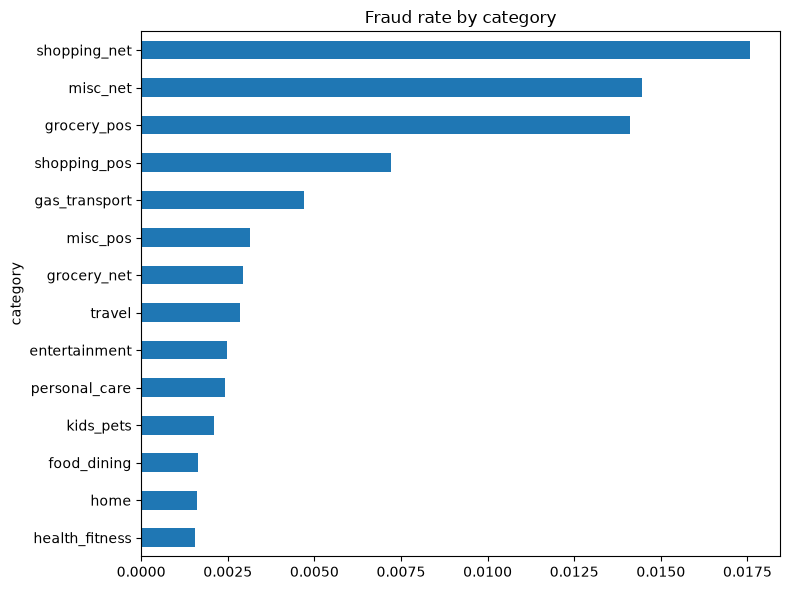

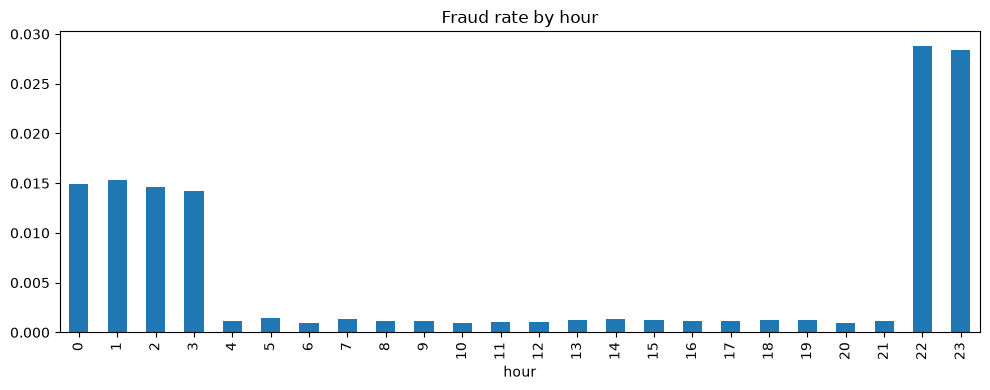

In [18]:
import matplotlib.pyplot as plt

cat = df.groupby("category")["is_fraud"].mean().sort_values()
cat.plot(kind="barh", figsize=(8, 6), title="Fraud rate by category")
plt.tight_layout()
plt.savefig("../docs/eda_category.png", dpi=150)
plt.show()

df.groupby("hour")["is_fraud"].mean().plot(kind="bar", figsize=(10, 4), title="Fraud rate by hour")
plt.tight_layout()
plt.savefig("../docs/eda_hour.png", dpi=150)
plt.show()

1- Fraud sirf 0.58% hai, to accuracy misleading hogi.
2- Online aur grocery categories mein fraud rate zyada hai.
3- Raat 0 se 3 baje fraud ka khatra sabse zyada hai.